### Case Study: **Santa María Volcano, Guatemala**

*Basic to Evolved - Subalkaline Calcalkaline*

[![Documentation](https://img.shields.io/badge/docs-latest-blue?logo=read-the-docs&logoColor=white)](https://hades-obol.readthedocs.io/en/latest/)
[![GitHub](https://img.shields.io/badge/GitHub-Hades-red?logo=github)](https://github.com/Jack6228/Hades)
[![PyPI](https://img.shields.io/pypi/v/hades-obol?logo=pypi&logoColor=white)](https://pypi.org/project/hades-obol/)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jack6228/Hades/blob/main/examples/guatemala/santa_maria.ipynb)

The Santa María volcano, Guatemala is an example of a calc-alkaline island arc setting whereby fractional crystallisation is the predominant compositional control mechanism to generate a primary to evolved suite of rocks.

> Note: This notebook is not intended to act as a tutorial directly, but to demonstrate this case study. See the [Hades Python Tutorial ↗](https://hades-obol.readthedocs.io/en/latest/api/tutorial.html) for more detailed explanations.

**Key links**: [GitHub Folder ↗](https://github.com/Jack6228/Hades/tree/main/examples/guatemala) | [Documentation Page ↗](https://hades-obol.readthedocs.io/en/latest/case_studies/guatemala/index.html) | [API Reference ↗](https://hades-obol.readthedocs.io/en/latest/api/index.html)

---

**Model Setup**

In [13]:
# Import the Obol class from the hades module and initialise a new model
from hades import Obol
model = Obol.newModel(
    submode='calcalkaline',
)

# Load the data suite
model.load_data_suite('./santa_maria.xlsx')

# Use Hades' default selection of the projected LLOD [automatically calculated]
model.select_initial_composition([None, None, 'samp. SM104', 'samp. S1120', 'samp. S1004', None])

Primary       : n/a
Primitive     : n/a
Basic         : 'samp. SM104'
Intermediate  : 'samp. S1120'
Evolved       : 'samp. S1004'
End           : n/a
3/6 phases have been set with user-provided initial compositions.


**Customisation**

Here, we can configure KD values, contributing minerals and their compositions

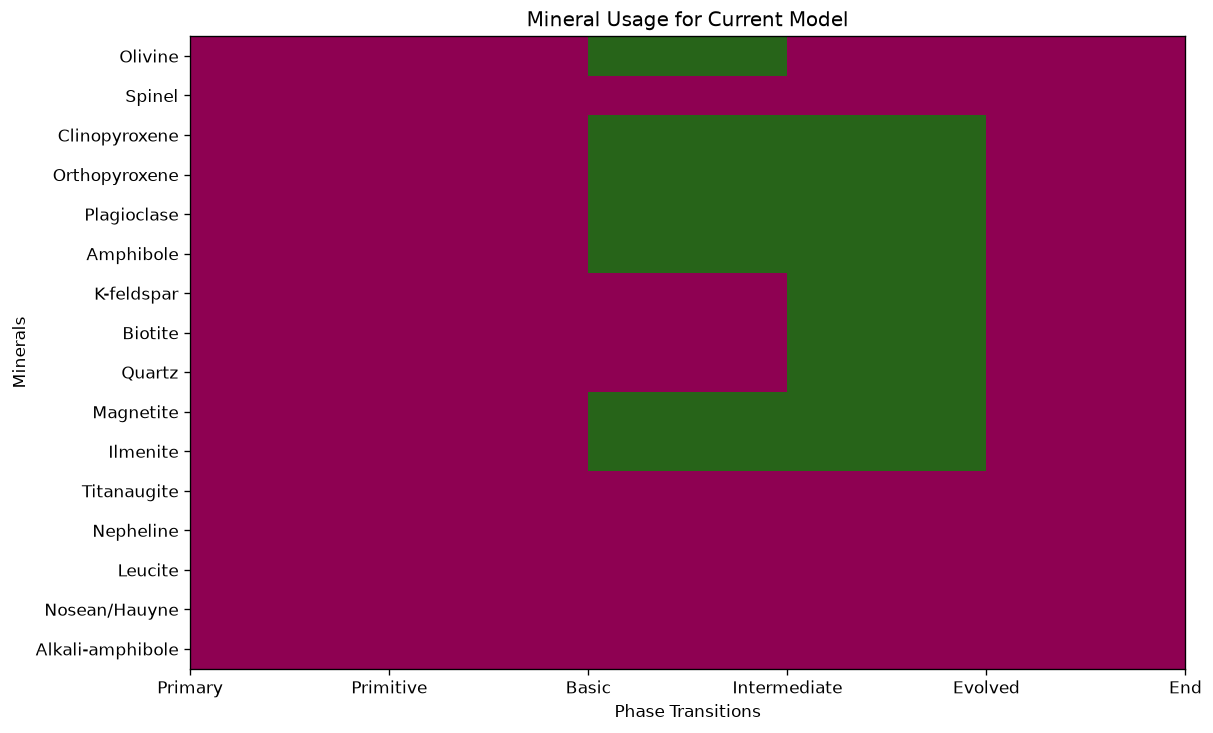

In [14]:
# Define which minerals contribute to the assemblage and in which phases
model.set_mineral_usage(
    __spinel=False,
    __cpx=True,
    __opx=True,
    __plagioclase=True,
    __mag=True,
    __ilm=True,
    intermediate__quartz=True,
    intermediate__kfeldspar=True,
    intermediate__biotite=True,
    intermediate__amphibole=True,
)

# Optionally: view the mineral usage configuration
from hades.visuals import mineral_usage
mineral_usage(
    model,
    filename='./outputs/mineral_usage.png',
)

In [15]:
# Specify the mineralogical compositions for minerals and phases (in wt.%)
model.set_mineralogies(
    intermediate__cpx =        [51.93, 0.20,  1.63, 10.43, 15.40, 19.79, 0.61, 0.00],
    intermediate__opx =        [52.06, 0.10,  0.79, 20.92, 24.95,  0.79, 0.39, 0.00],
    intermediate__plagioclase =       [56.26, 0.00, 27.83,  0.33,  0.10,  9.75, 5.53, 0.20],
    intermediate__amphibole =  [42.78, 2.34, 11.79, 14.34, 15.04, 10.77, 2.54, 0.41],
    intermediate__magnetite =  [ 0.67, 7.42,  2.70, 87.18,  1.74,  0.19, 0.10, 0.00],
)

Normalising composition for intermediate__cpx to 100 wt%. Original sum: 99.99
Normalising composition for intermediate__amphibole to 100 wt%. Original sum: 100.01


In [16]:
# Set experimental or literature-based KD values for the minerals and phases 
model.set_KDs(
    evolved__plagioclase=3.4, 
)

**Optimisation**

In [17]:
# Run stages 3 and 4 (basic-intermediate-evolved)
model.run(3)
model.run(4)

> Optimisation completed with cost = 0.33 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'
> Optimisation completed with cost = 0.24 after 500/500 iters and 501 func. evals with population size 50 because of: 'Maximum number of iterations has been exceeded.'


We can view the results for the entire model:

In [18]:
model.summary()

                        B-I        I-E     |     Total   
----------------------------------------------------------------
            Type  |    Majors     Majors   |            
            Cost  |      0.33       0.24   |            
----------------------------------------------------------------
               F  |        30         43   |       100    %
         Olivine  |    21.216              |    10.590    wt.%
          Spinel  |                        |              wt.%
   Clinopyroxene  |     8.873     14.721   |    11.802    wt.%
   Orthopyroxene  |     0.472      2.336   |     1.405    wt.%
     Plagioclase  |    61.903     62.418   |    62.161    wt.%
       Amphibole  |     1.442     11.240   |     6.349    wt.%
      K-feldspar  |                0.115   |     0.058    wt.%
         Biotite  |                0.402   |     0.201    wt.%
          Quartz  |                0.109   |     0.054    wt.%
       Magnetite  |     5.151      7.574   |     6.365    wt.%
        

**Visualising Results**

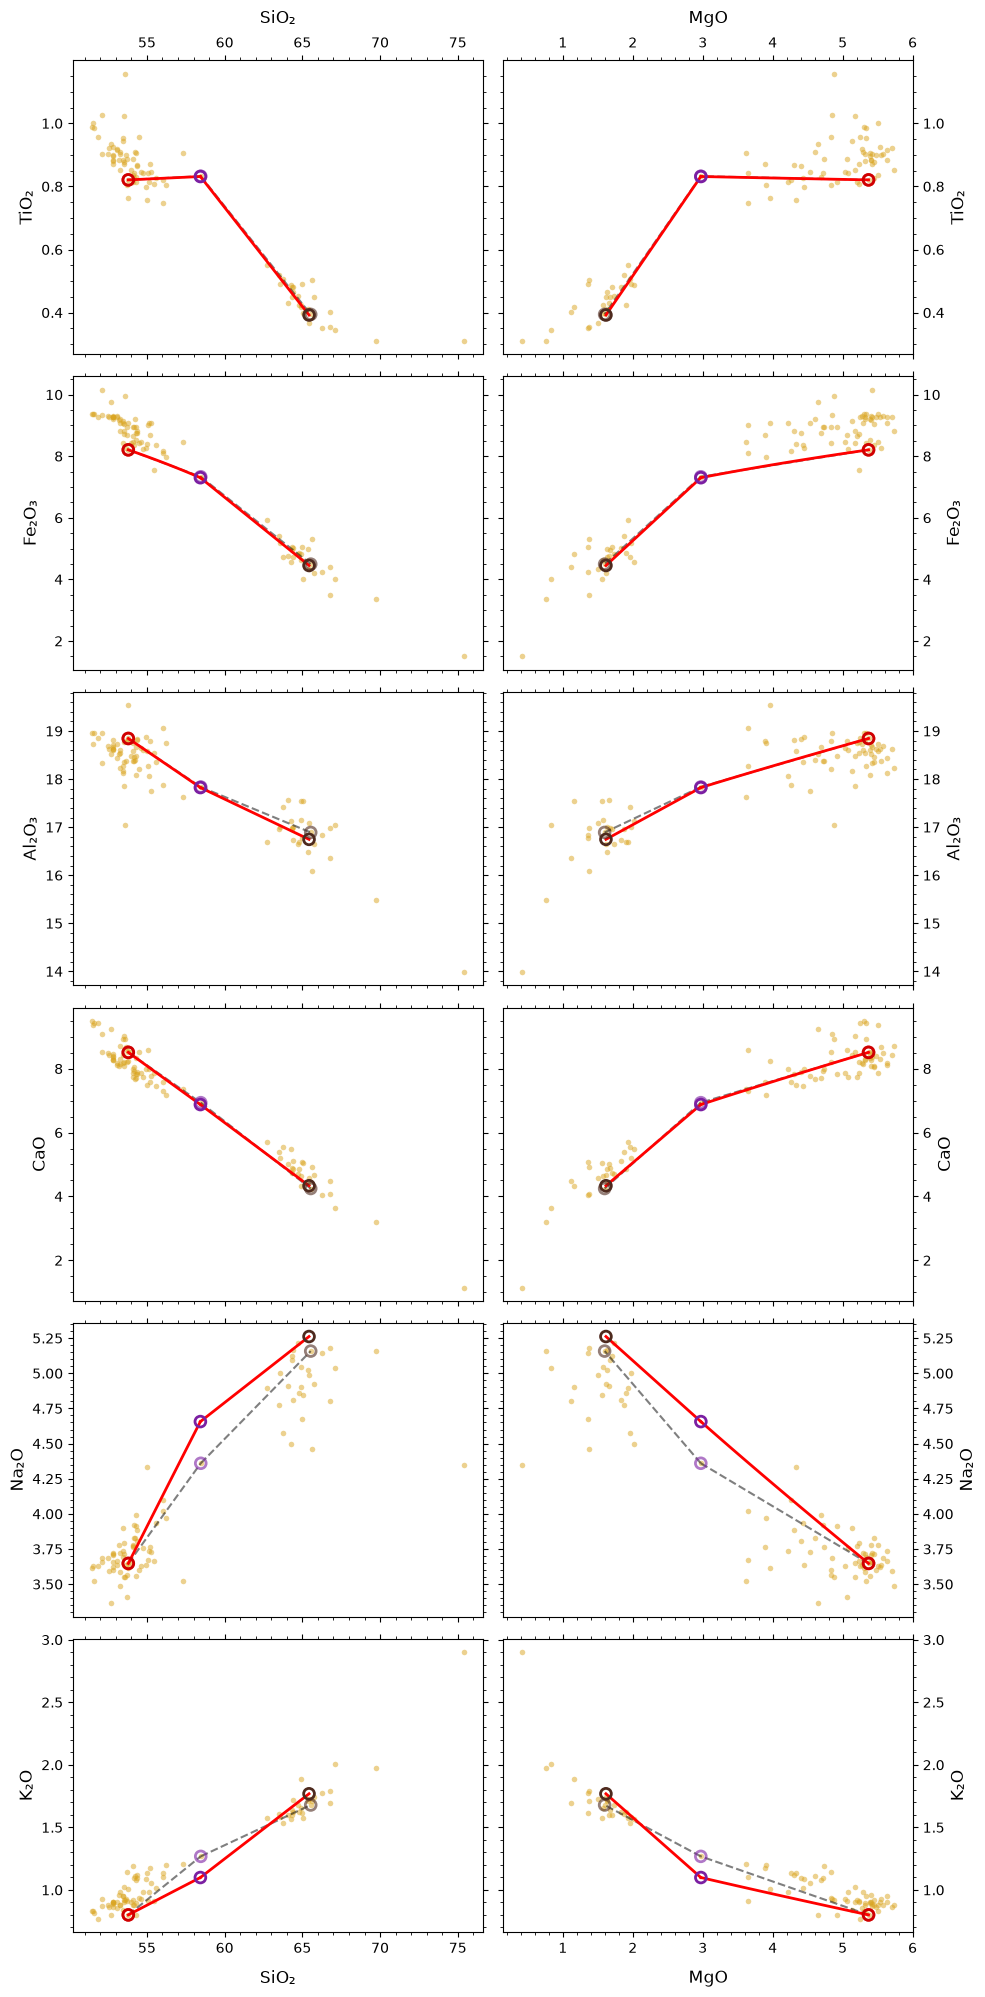

In [19]:
# Plot bivariate plots for the major oxides and save to a file
from hades.visuals import bivar
bivar(
    model, 
    y_order=['TiO2', 'Fe2O3', 'Al2O3', 'CaO', 'Na2O', 'K2O'], 
    filename='./outputs/bivariate_plots.png',
)

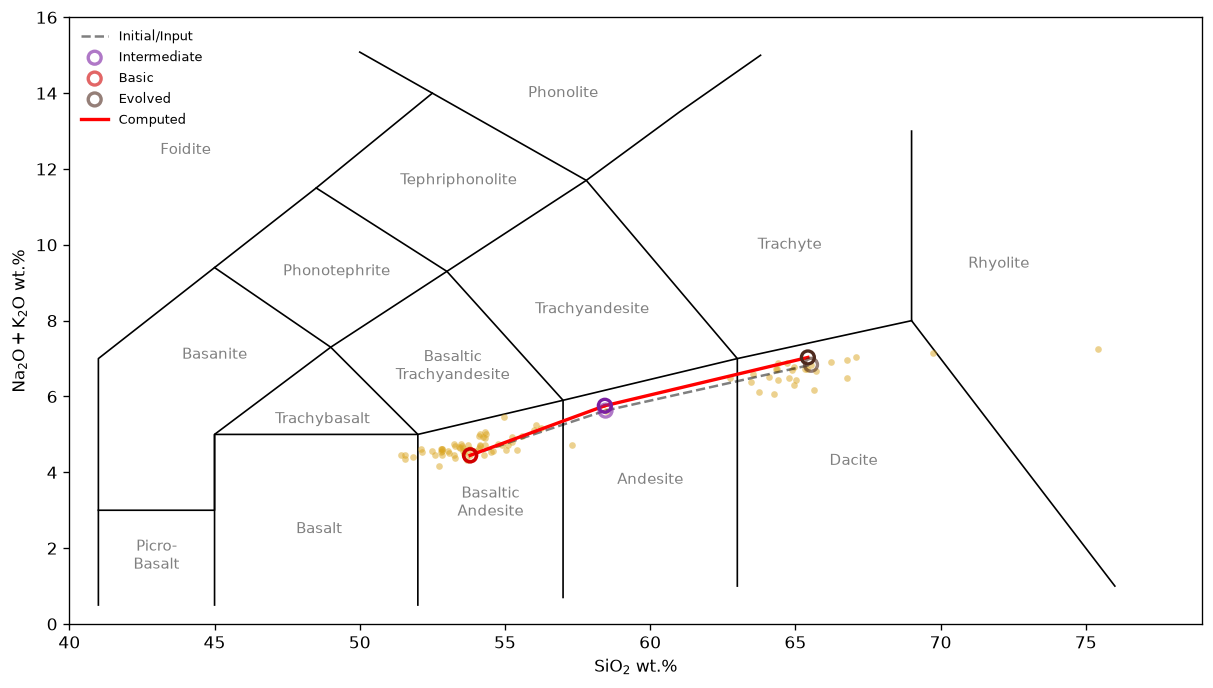

In [20]:
# Plot the TAS diagram and save to a file
from hades.visuals import tas
tas(
    model, 
    filename='./outputs/tas_diagram.png'
)

**Export Results**

In [9]:
model.savePDF('./outputs/results.pdf')
model.saveData('./outputs/data_output.xlsx')

PDF compilation completed. Output saved to ./outputs/results.pdf
Excel file saved successfully: ./outputs/data_output.xlsx


----

**Useful Commands**

Configuration Files

Having imported data and configured our desired parameters, we can save the configuration to a ``.hades`` file. This allows us to easily reload the model configuration in the future (either in Python or the Hades Windows application) without having to re-import data or reconfigure parameters.

See the documentation for more information on [saving and loading model configurations](https://hades-obol.readthedocs.io/en/latest/user_manual/config_files.html).

In [10]:
model.save_config('./santa_maria.hades')

Successfully saved configuration to ./santa_maria.hades


To use a ``.hades`` configuration file to initialise a model, simply create a fresh model and call the ``load_config`` method with the path to the configuration file. This will automatically import the data and set all parameters as specified in the configuration file, overwriting any arguments passed to the ``newModel`` method.

In [11]:
model = Obol.newModel()
model.load_config('./santa_maria.hades')

 To adjust the population size and maximum number of generations, you can use the following code before running the model

In [12]:
# model.optimising.max_iter = 500 # default
# model.optimising.pop_size = 50  # default